# 발표용 표와 그래프

학술제 예선 발표의 단계별 표 수치와 그래프를 실제 작업 결과 파일에서 읽어 만든다.

- 입력: `data/results/*.csv` (06~14번 결과), `data/eda/*.csv` (02번), `data/target/` (04번), `data/features/` (05번), `data/cleaned/` (03번)
- 출력: `charts/presentation/*.png`
- 실행 순서: 저장소의 01~14번 스크립트를 먼저 돌린 뒤 이 노트북을 위에서부터 실행한다. 결과 파일이 없는 칸은 건너뛴다.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

# notebooks/에서 열면 한 단계 위가 저장소 루트
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RES = os.path.join(ROOT, "data", "results")
OUT = os.path.join(ROOT, "charts", "presentation")
os.makedirs(OUT, exist_ok=True)
PUMP = "1.펌프_일반모터"

plt.style.use("default")
have = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "WenQuanYi Zen Hei"]:
    if name in have:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def read(path):
    full = os.path.join(ROOT, path)
    if not os.path.exists(full):
        print("없음, 건너뜀:", path)
        return None
    return pd.read_csv(full)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, name), dpi=150)
    plt.show()


print("저장소 루트:", ROOT)

저장소 루트: /home/claude/sch_thesis


## 1. 주제 소개와 문제 설정

표 1. 예측 구간별 양성 비율 (펌프/일반모터, 정상 운전 시점 중 N분 안에 이상이 시작되는 비율)

In [2]:
ts = read("data/target/target_summary.csv")
if ts is not None:
    ts = ts[ts["facility"] == PUMP]
    rows = []
    for split, g in ts.groupby("split"):
        r = {"split": split}
        for h in [10, 30, 60]:
            pos, neg = g[f"pos_{h}"].sum(), g[f"neg_{h}"].sum()
            r[f"{h}분 양성 비율(%)"] = round(100 * pos / (pos + neg), 2)
        r["예측 대상 시점"] = int(g["pos_30"].sum() + g["neg_30"].sum())
        rows.append(r)
    display(pd.DataFrame(rows))

,split,10분 양성 비율(%),30분 양성 비율(%),60분 양성 비율(%),예측 대상 시점
0,Training,1.60,3.28,4.89,950414
1,Validation,1.75,3.93,6.38,133322


그림 1. 실제 이상 발생 사례: 정상 운전 중 30분 안에 이상이 시작되는지 맞히는 문제

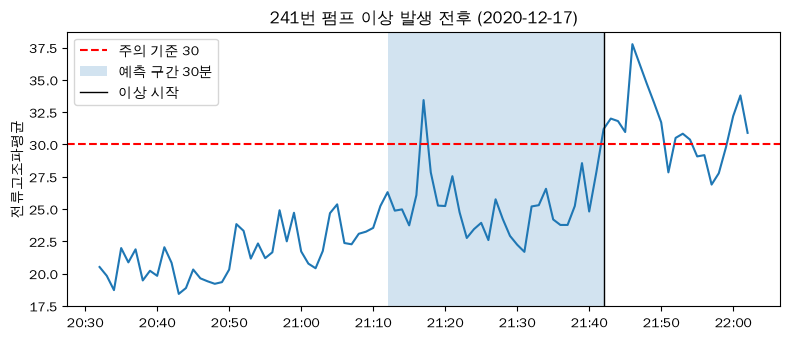

이상 시작: 2020-12-17 21:42:00


In [3]:
# 241번 펌프 Validation 기간에서 직전 30분이 모두 예측 대상인 첫 사건을 고름
DEV = 241
t = pd.read_parquet(os.path.join(ROOT, "data", "target", "Validation", PUMP, f"{DEV}.parquet"))
s = pd.read_parquet(os.path.join(ROOT, "data", "cleaned", "Validation", PUMP, f"{DEV}.parquet"),
                    columns=["전류고조파평균"])["전류고조파평균"]
ok_before = t["eligible"].rolling(30).sum().shift(1) == 30
onset = t.index[(t["event_start"] == 1) & ok_before][0]
w = s.loc[onset - pd.Timedelta(minutes=70): onset + pd.Timedelta(minutes=20)]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(w.index, w.values)
ax.axhline(30, color="r", ls="--", label="주의 기준 30")
ax.axvspan(onset - pd.Timedelta(minutes=30), onset, alpha=0.2, label="예측 구간 30분")
ax.axvline(onset, color="k", lw=1, label="이상 시작")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylabel("전류고조파평균")
ax.set_title(f"{DEV}번 펌프 이상 발생 전후 ({onset:%Y-%m-%d})")
ax.legend(loc="upper left")
save(fig, "1_example_event.png")
print("이상 시작:", onset)

## 2. 데이터 소개와 EDA

표 2. 설비 구성과 기간

In [4]:
dev = read("data/eda/device_summary.csv")
if dev is not None:
    dev["start"], dev["end"] = pd.to_datetime(dev["start"]), pd.to_datetime(dev["end"])
    display(dev.groupby(["facility", "split"]).agg(설비_수=("dev", "nunique"), 행_수=("n_rows", "sum"),
                                                   시작=("start", "min"), 끝=("end", "max")))

설비_수      행_수                  시작                   끝
facility  split                                                            
1.펌프_일반모터 Training      73  2403440 2020-10-07 00:00:00 2021-02-06 16:27:13
          Validation    73   315543 2020-11-20 00:00:08 2021-02-08 23:59:47
2.공조설비    Training      32  1084183 2020-09-16 00:00:00 2021-02-05 23:59:59
          Validation    32   135872 2020-10-23 00:00:38 2021-02-07 23:59:59

표 3. 설비 종류별 이상 발생 사건 수와 30분 양성 수 (공조설비를 뺀 근거)

In [5]:
ts_all = read("data/target/target_summary.csv")
if ts_all is not None:
    display(ts_all.groupby(["facility", "split"])[["events", "eligible", "pos_30"]].sum())

events  eligible  pos_30
facility  split                               
1.펌프_일반모터 Training      3036    951734   31136
          Validation     523    134021    5240
2.공조설비    Training        56    386585      19
          Validation      15     46212       0

표 4. SOH 라벨이 고정 기준값만으로 재현되는 비율 (운전 구간)

In [6]:
m = read("data/eda/soh_rule_match.csv")
if m is not None:
    display(m.rename(columns={m.columns[0]: "라벨"}))

,라벨,rule_match
0,label_SOH_역률평균,0.9744
1,label_SOH_전류고조파평균,0.9912
2,label_SOH_전압고조파평균,0.9822


표 5. 기동 상태별 SOH 라벨 분포 (역률 '경고'가 정지 구간에 몰려 있음)

In [7]:
p = os.path.join(ROOT, "data", "eda", "soh_by_state.csv")
if os.path.exists(p):
    display(pd.read_csv(p, header=[0, 1], index_col=0).dropna(how="all"))

label_SOH_역률평균                 label_SOH_전류고조파평균                 label_SOH_전압고조파평균                
label_SOH_역률평균             경고      정상      주의                경고      정상      주의                경고      정상      주의
label_기동_전류평균                                                                                                    
Loading                0.1337  0.5402  0.3261            0.2202  0.6695  0.1103            0.3920  0.2431  0.3649
Stop                   0.9291  0.0527  0.0182            0.0043  0.9678  0.0279            0.2916  0.4658  0.2426
Unloading              0.1782  0.5100  0.3119            0.1222  0.6505  0.2274            0.3972  0.2806  0.3222

그림 2. 이상 구간 지속 시간 분포 (5분 미만 깜빡임을 사건에서 뺀 근거)

이상 구간 6,750개, 5분 미만 47.3%


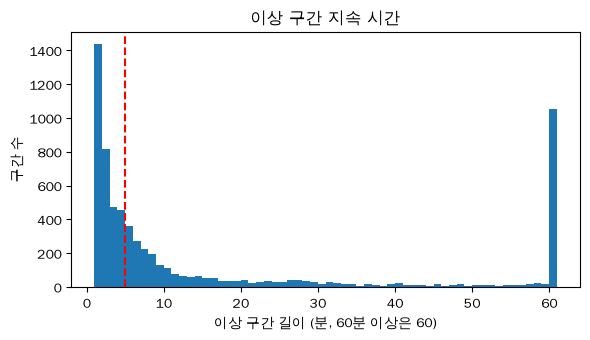

In [8]:
lengths = []
for f in glob.glob(os.path.join(ROOT, "data", "target", "*", PUMP, "*.parquet")):
    a = pd.read_parquet(f, columns=["is_abnormal"])["is_abnormal"].to_numpy()
    edges = np.flatnonzero(np.diff(np.r_[0, a, 0]))
    lengths.extend(edges[1::2] - edges[::2])
lengths = np.array(lengths)
print(f"이상 구간 {len(lengths):,}개, 5분 미만 {np.mean(lengths < 5):.1%}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.clip(lengths, 1, 60), bins=np.arange(1, 62))
ax.axvline(5, color="r", ls="--")
ax.set_xlabel("이상 구간 길이 (분, 60분 이상은 60)")
ax.set_ylabel("구간 수")
ax.set_title("이상 구간 지속 시간")
save(fig, "2_abnormal_run_length.png")

그림 3. 30분 안 이상 발생 여부별 최근 60분 전류고조파 최댓값 (Training)

target_30
0.0     8.561198
1.0    36.588543
Name: 중앙값, dtype: float32


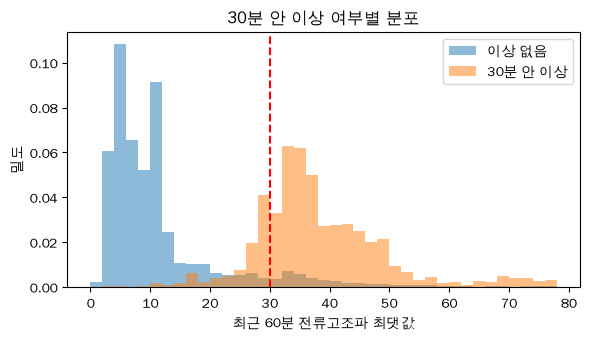

In [9]:
parts = [pd.read_parquet(f, columns=["전류고조파평균_max60", "target_30"])
         for f in glob.glob(os.path.join(ROOT, "data", "features", "Training", PUMP, "*.parquet"))]
fe = pd.concat(parts).dropna()
print(fe.groupby("target_30")["전류고조파평균_max60"].median().rename("중앙값"))

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.arange(0, 80, 2)
ax.hist(fe.loc[fe["target_30"] == 0, "전류고조파평균_max60"], bins=bins, density=True, alpha=0.5, label="이상 없음")
ax.hist(fe.loc[fe["target_30"] == 1, "전류고조파평균_max60"], bins=bins, density=True, alpha=0.5, label="30분 안 이상")
ax.axvline(30, color="r", ls="--")
ax.set_xlabel("최근 60분 전류고조파 최댓값")
ax.set_ylabel("밀도")
ax.legend()
ax.set_title("30분 안 이상 여부별 분포")
save(fig, "3_max60_by_target.png")

## 3. 모델링 방향과 초기 모델 결과

표 6. 베이스라인 (Training으로 학습·임계값, Validation 평가)

In [10]:
COLS = ["pr_auc", "precision", "recall", "f1", "event_recall", "lead_median", "false_alarm_per_day"]
b = read("data/results/baseline_metrics.csv")
if b is not None:
    display(b.set_index("model")[COLS].round(3))

,pr_auc,precision,recall,f1,event_recall,lead_median,false_alarm_per_day
model,,,,,,,
항상 음성,0.039,0.000,0.000,0.000,0.000,NaN,0.000
규칙: 현재 전류고조파,0.327,0.384,0.450,0.415,0.839,8.0,17.044
규칙: 최근 10분 전류고조파 최댓값,0.225,0.269,0.631,0.378,0.963,9.0,14.689
Logistic Regression,0.486,0.458,0.598,0.518,0.865,9.0,8.889


표 7. 모델 비교 (Training 앞 80% 학습, 뒤 20%로 임계값, Validation 평가)

In [11]:
mm = read("data/results/model_metrics.csv")
if mm is not None:
    display(mm.set_index("model")[COLS].round(3))

,pr_auc,precision,recall,f1,event_recall,lead_median,false_alarm_per_day
model,,,,,,,
규칙: 현재 전류고조파,0.327,0.296,0.731,0.421,0.913,13.0,16.633
Logistic Regression (이력 없음 중앙값),0.449,0.370,0.690,0.482,0.924,11.0,10.974
Logistic Regression (이력 없음 표시),0.485,0.360,0.758,0.488,0.927,11.0,10.585
Random Forest,0.702,0.591,0.702,0.641,0.868,9.5,2.905
LightGBM,0.738,0.656,0.648,0.652,0.854,10.0,3.489


그림 4. 모델별 PR-AUC (같은 설비의 뒤 기간)

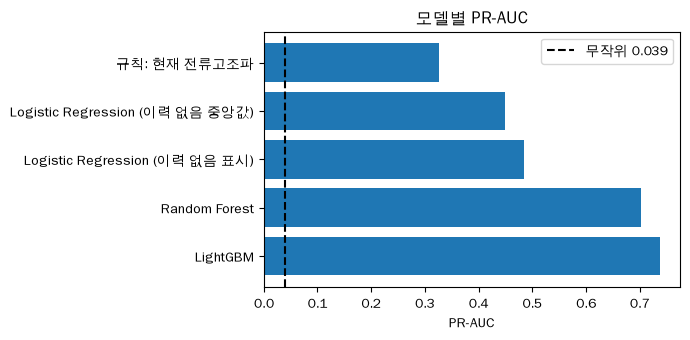

In [12]:
if mm is not None and b is not None:
    rand = b.set_index("model").loc["항상 음성", "pr_auc"]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(mm["model"], mm["pr_auc"])
    ax.axvline(rand, color="k", ls="--", label=f"무작위 {rand:.3f}")
    ax.invert_yaxis()
    ax.set_xlabel("PR-AUC")
    ax.legend(loc="upper right")
    ax.set_title("모델별 PR-AUC")
    save(fig, "4_model_pr_auc.png")

## 4. 작업 중 생긴 이슈와 해결

이슈 1. 같은 설비의 앞 기간으로 학습하면 설비를 외운다 → 설비 단위 5묶음 분할로 평가

표 8. 본 적 있는 설비와 처음 보는 설비

In [13]:
us = read("data/results/unit_split_metrics.csv")
if us is not None:
    display(us.pivot(index="model", columns="setting", values="pr_auc").round(3))
    display(us.set_index(["setting", "model"])[COLS].round(3))

setting,본 적 있는 설비,처음 보는 설비
model,,
LightGBM,0.738,0.470
Logistic Regression,0.485,0.396
규칙,0.327,0.327


pr_auc  precision  recall     f1  event_recall  lead_median  false_alarm_per_day
setting   model                                                                                                
본 적 있는 설비 규칙                    0.327      0.295   0.731  0.421         0.912         13.0               16.634
          Logistic Regression   0.485      0.360   0.758  0.488         0.927         11.0               10.585
          LightGBM              0.738      0.656   0.648  0.652         0.853         10.0                3.489
처음 보는 설비  규칙                    0.327      0.345   0.480  0.402         0.839          9.0               19.334
          Logistic Regression   0.396      0.402   0.633  0.491         0.833         10.0                8.468
          LightGBM              0.470      0.418   0.545  0.473         0.811         10.0                8.371

표 9. 묶음별 처음 보는 설비 PR-AUC

In [14]:
uf = read("data/results/unit_split_folds.csv")
if uf is not None:
    display(uf[uf["setting"] == "처음 보는 설비"].pivot(index="model", columns="fold", values="pr_auc").round(3))

fold,0,1,2,3,4
model,,,,,
LightGBM,0.325,0.710,0.448,0.863,0.587
Logistic Regression,0.237,0.514,0.447,0.703,0.248
규칙,0.216,0.540,0.498,0.802,0.193


그림 5. 학습에 그 설비를 넣었을 때와 뺐을 때

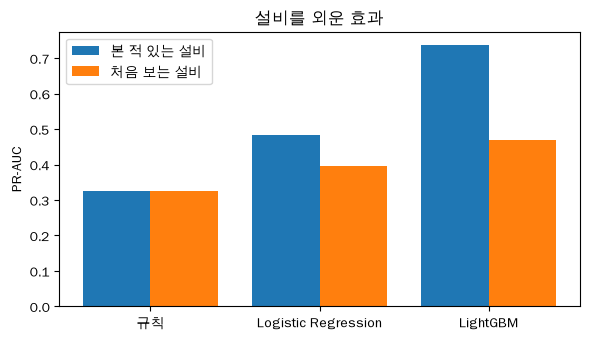

In [15]:
if us is not None:
    p = us.pivot(index="model", columns="setting", values="pr_auc").loc[["규칙", "Logistic Regression", "LightGBM"]]
    x = np.arange(len(p))
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(x - 0.2, p["본 적 있는 설비"], width=0.4, label="본 적 있는 설비")
    ax.bar(x + 0.2, p["처음 보는 설비"], width=0.4, label="처음 보는 설비")
    ax.set_xticks(x, p.index)
    ax.set_ylabel("PR-AUC")
    ax.legend()
    ax.set_title("설비를 외운 효과")
    save(fig, "5_seen_vs_unseen.png")

이슈 2. 1분짜리 경보가 많아 오경보가 쌓인다 → 경보가 N분 이어질 때만 알림

표 10. 대기 시간별 사건 재현율과 하루 오경보

In [16]:
ar = read("data/results/alarm_rule_metrics.csv")
if ar is not None:
    display(ar.pivot(index="wait_min", columns="model", values="event_recall").round(3))
    display(ar.pivot(index="wait_min", columns="model", values="false_alarm_per_day").round(2))

model,LightGBM,Logistic Regression (이력 없음 표시),규칙: 현재 전류고조파
wait_min,,,
1,0.854,0.927,0.913
2,0.738,0.823,0.746
3,0.603,0.676,0.572
5,0.507,0.569,0.462
10,0.341,0.403,0.358


model,LightGBM,Logistic Regression (이력 없음 표시),규칙: 현재 전류고조파
wait_min,,,
1,3.49,10.58,16.63
2,2.00,6.11,6.70
3,1.39,4.06,3.61
5,0.77,2.66,1.91
10,0.31,1.34,0.71


그림 6. 대기 시간(1~10분)에 따른 오경보와 사건 재현율

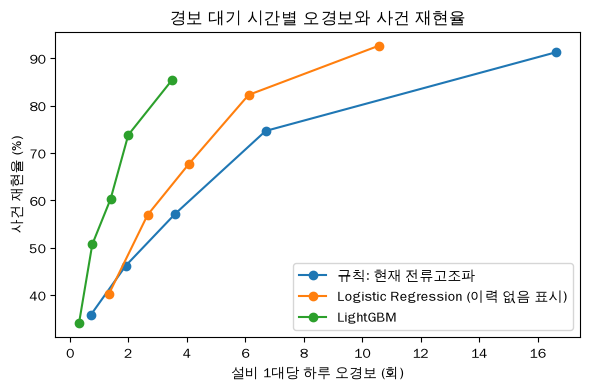

In [17]:
if ar is not None:
    fig, ax = plt.subplots(figsize=(6, 4))
    for model, g in ar.groupby("model", sort=False):
        g = g.sort_values("wait_min")
        ax.plot(g["false_alarm_per_day"], g["event_recall"] * 100, marker="o", label=model)
    ax.set_xlabel("설비 1대당 하루 오경보 (회)")
    ax.set_ylabel("사건 재현율 (%)")
    ax.legend()
    ax.set_title("경보 대기 시간별 오경보와 사건 재현율")
    save(fig, "6_alarm_tradeoff.png")

이슈 3. 공조설비는 Validation 사건이 0건이라 평가 불가 → 펌프/일반모터만 분석 (표 3)

이슈 4. 이상 구간 절반 가까이가 5분 미만 깜빡임 → 5분 이상 이어진 이상만 사건으로 정의 (그림 2)

## 5. 개선 시도

표 11. 설비별 평소 값 대비 특징(z) 추가 전후

In [18]:
un = read("data/results/unit_split_norm_metrics.csv")
if us is not None and un is not None:
    both = pd.concat([us.assign(특징="기존"), un.assign(특징="+ z 33개")])
    display(both.set_index(["setting", "model", "특징"])[["pr_auc", "event_recall", "false_alarm_per_day"]]
            .sort_index().round(3))

pr_auc  event_recall  false_alarm_per_day
setting   model               특징                                                
본 적 있는 설비 LightGBM            + z 33개   0.721         0.867                3.640
                              기존        0.738         0.853                3.489
          Logistic Regression + z 33개   0.511         0.898                9.408
                              기존        0.485         0.927               10.585
          규칙                  + z 33개   0.327         0.912               16.634
                              기존        0.327         0.912               16.634
처음 보는 설비  LightGBM            + z 33개   0.441         0.726                7.410
                              기존        0.470         0.811                8.371
          Logistic Regression + z 33개   0.421         0.831                8.500
                              기존        0.396         0.833                8.468
          규칙                  + z 33개   0.327         0.839               19.334
                              기존        0.327         0.839               19.334

표 12. 선행 연구 방식 재현: 값 예측 후 판정

In [19]:
vf = read("data/results/value_forecast_metrics.csv")
if vf is not None:
    display(vf.set_index(["setting", "model"])[COLS].round(3))

pr_auc  precision  recall     f1  event_recall  lead_median  false_alarm_per_day
setting   model                                                                                                     
본 적 있는 설비 값 예측 후 판정 (기준값 30)         0.233      0.273   0.842  0.412         0.986         12.0               16.504
          값 예측 후 판정 (F1 최대 임계값)      0.233      0.271   0.791  0.404         0.980         11.0               16.590
처음 보는 설비  값 예측 후 판정 (기준값 30)         0.222      0.251   0.741  0.375         0.963         11.0               20.716
          값 예측 후 판정 (F1 최대 임계값)      0.222      0.260   0.717  0.381         0.963         11.0               20.749
참고        완벽한 값 예측 (실제 다음 30분 최댓값)   0.323      0.385   1.000  0.556         1.000         13.0               12.918

표 13. Transformer (원시 60분 시계열)

In [20]:
tf = read("data/results/transformer_metrics.csv")
tff = read("data/results/transformer_folds.csv")
if tf is not None:
    display(tf.set_index("setting")[COLS].round(3))
if tff is not None:
    display(tff.pivot(index="setting", columns="fold", values="pr_auc").round(3))

,pr_auc,precision,recall,f1,event_recall,lead_median,false_alarm_per_day
setting,,,,,,,
본 적 있는 설비,0.657,0.547,0.674,0.604,0.870,10.0,7.507
처음 보는 설비,0.416,0.377,0.487,0.425,0.667,12.0,9.429


fold,0,1,2,3,4
setting,,,,,
본 적 있는 설비,0.453,0.685,0.669,0.875,0.581
처음 보는 설비,0.229,0.572,0.567,0.840,0.209


그림 7. 방식별 처음 보는 설비 PR-AUC

,방식,pr_auc
2,값 예측 후 판정,0.222
0,규칙,0.327
1,Logistic Regression,0.396
4,Transformer,0.416
3,LightGBM + z 특징,0.441
5,LightGBM,0.470


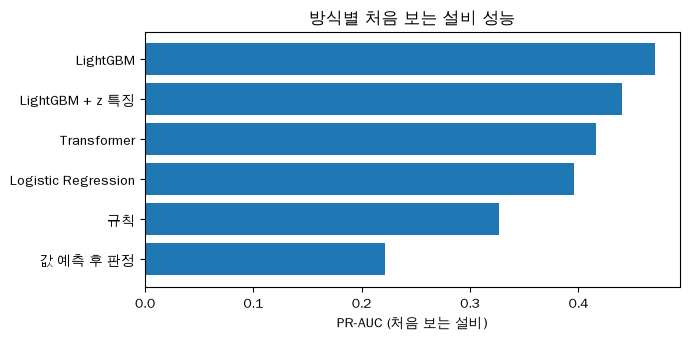

In [21]:
rows = []
if us is not None:
    u = us[us["setting"] == "처음 보는 설비"].set_index("model")["pr_auc"]
    rows += [("규칙", u["규칙"]), ("Logistic Regression", u["Logistic Regression"])]
if vf is not None:
    rows.append(("값 예측 후 판정", vf.set_index(["setting", "model"]).loc[("처음 보는 설비", "값 예측 후 판정 (기준값 30)"), "pr_auc"]))
if un is not None:
    rows.append(("LightGBM + z 특징", un.set_index(["setting", "model"]).loc[("처음 보는 설비", "LightGBM"), "pr_auc"]))
if tf is not None:
    rows.append(("Transformer", tf.set_index("setting").loc["처음 보는 설비", "pr_auc"]))
if us is not None:
    rows.append(("LightGBM", u["LightGBM"]))
if rows:
    r = pd.DataFrame(rows, columns=["방식", "pr_auc"]).sort_values("pr_auc")
    display(r.round(3))
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(r["방식"], r["pr_auc"])
    ax.set_xlabel("PR-AUC (처음 보는 설비)")
    ax.set_title("방식별 처음 보는 설비 성능")
    save(fig, "7_approach_unseen.png")

## 6. 최종 모델 결과

표 14. 예측 구간과 라벨을 바꿨을 때 처음 보는 설비 PR-AUC, 묶음별 LightGBM 우세 수

In [22]:
runs = [("전류고조파 10분", "h10"), ("전류고조파 30분", ""), ("전류고조파 60분", "h60"), ("전압고조파 30분", "vh")]
rows = []
for label, tag in runs:
    sfx = f"_{tag}" if tag else ""
    met, fol = read(f"data/results/unit_split{sfx}_metrics.csv"), read(f"data/results/unit_split{sfx}_folds.csv")
    if met is None or fol is None:
        continue
    u = met[met["setting"] == "처음 보는 설비"].set_index("model")
    f = fol[fol["setting"] == "처음 보는 설비"].pivot(index="fold", columns="model", values="pr_auc")
    rows.append({"조건": label, "양성 비율": u["positive_rate"].iloc[0], "규칙": u.loc["규칙", "pr_auc"],
                 "Logistic Regression": u.loc["Logistic Regression", "pr_auc"], "LightGBM": u.loc["LightGBM", "pr_auc"],
                 "LightGBM 우세 묶음": f"{int((f['LightGBM'] > f['규칙']).sum())} / {len(f)}"})
cond = pd.DataFrame(rows)
display(cond.round(3))

,조건,양성 비율,규칙,Logistic Regression,LightGBM,LightGBM 우세 묶음
0,전류고조파 10분,0.017,0.188,0.197,0.327,5 / 5
1,전류고조파 30분,0.039,0.327,0.396,0.470,4 / 5
2,전류고조파 60분,0.064,0.439,0.542,0.596,5 / 5
3,전압고조파 30분,0.080,0.402,0.574,0.645,5 / 5


그림 8. 조건별 처음 보는 설비 PR-AUC

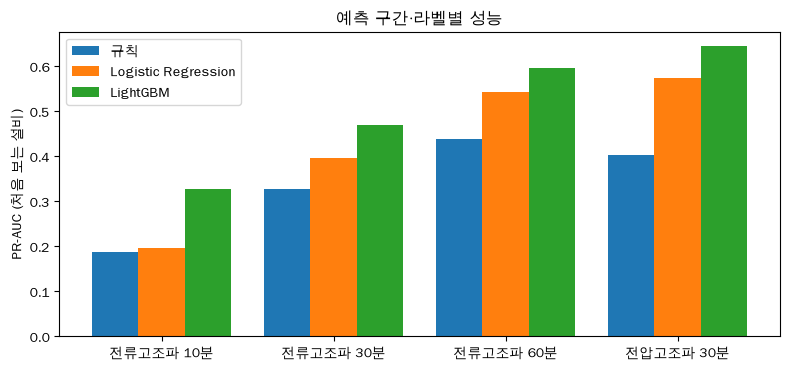

In [23]:
if len(cond):
    x = np.arange(len(cond))
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for j, m in enumerate(["규칙", "Logistic Regression", "LightGBM"]):
        ax.bar(x + (j - 1) * 0.27, cond[m], width=0.27, label=m)
    ax.set_xticks(x, cond["조건"])
    ax.set_ylabel("PR-AUC (처음 보는 설비)")
    ax.legend()
    ax.set_title("예측 구간·라벨별 성능")
    save(fig, "8_condition_unseen.png")

표 15. LightGBM이 본 신호 (SHAP 평균 |값| 상위 10개)

In [24]:
sh = read("data/results/shap_importance.csv")
if sh is not None:
    top = sh.head(10)[["feature", "share", "mean_shap_pos", "mean_shap_neg"]]
    display(top.round(3))
    print(f"상위 2개 합 {sh['share'].head(2).sum():.1%}, 전류고조파평균 계열 합 {sh.loc[sh['feature'].str.startswith('전류고조파평균'), 'share'].sum():.1%}")

,feature,share,mean_shap_pos,mean_shap_neg
0,마지막이상후_분,0.274,2.254,-0.086
1,전류고조파평균_max60,0.213,2.317,-0.095
2,전류고조파평균_max30,0.078,0.948,-0.022
3,전류고조파평균,0.045,0.684,-0.003
4,전류고조파평균_mean10,0.024,0.262,-0.032
5,전류고조파평균_mean30,0.014,0.125,-0.028
6,전류고조파평균_max10,0.013,0.157,-0.005
7,이상비율_60,0.013,0.107,-0.024
8,주파수_std60,0.011,0.004,-0.012
9,주파수_max30,0.011,0.044,0.018


상위 2개 합 48.7%, 전류고조파평균 계열 합 40.7%


그림 9. SHAP 상위 10개 특징

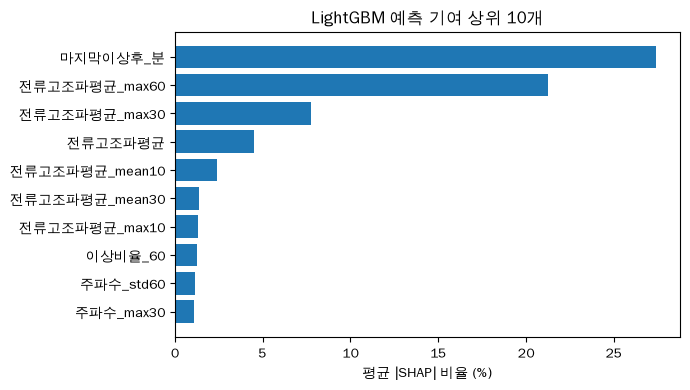

In [25]:
if sh is not None:
    top = sh.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(top["feature"], top["share"] * 100)
    ax.set_xlabel("평균 |SHAP| 비율 (%)")
    ax.set_title("LightGBM 예측 기여 상위 10개")
    save(fig, "9_shap_top10.png")

## 7. 한계

표 16. 새 설비에 쓸 때의 차이 (LightGBM)

In [26]:
if us is not None:
    display(us[us["model"] == "LightGBM"].set_index("setting")[["pr_auc", "event_recall", "false_alarm_per_day"]].round(3))
if uf is not None:
    g = uf[(uf["setting"] == "처음 보는 설비") & (uf["model"] == "LightGBM")]["pr_auc"]
    print(f"묶음별 처음 보는 설비 LightGBM PR-AUC 범위 {g.min():.3f} ~ {g.max():.3f}")

,pr_auc,event_recall,false_alarm_per_day
setting,,,
본 적 있는 설비,0.738,0.853,3.489
처음 보는 설비,0.470,0.811,8.371


묶음별 처음 보는 설비 LightGBM PR-AUC 범위 0.325 ~ 0.863
